# 04 — EMT-TF Expression · Wang et al. 2019 (Glioblastoma)

Unconditional final step (Gate 3 = NA → this is notebook 04). Derive the most informative EMT transcription factors for THIS dataset — detection-gated, spanning mesenchymal families beyond Snail/Zeb/Twist (FOXC, PRRX) — and overlay thresholded expressers categorically on the grey manifold (VIM excluded: it is a mesenchymal marker, not a TF).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
category = os.path.split(os.path.split(os.getcwd())[0])[1]
pth = os.path.join(*(['..'] * 6))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)

### Load processed data (per §6 the expression step reads `processed.h5ad`)
Pseudotime from `manifold.h5ad` is merged in only to order the candidate TFs (root vs terminus); the plotted manifold and expression come from `processed.h5ad`.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
man = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
adata.obs['t'] = man.obs['t'].reindex(adata.obs_names)
adata

AnnData object with n_obs × n_vars = 9616 × 26409
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'leiden', 'sc_AC-like', 'sc_MES-like', 'sc_NPC-like', 'sc_OPC-like', 'S_score', 'G2M_score', 'phase', 'cyc_score', 't'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'celltype_colors', 'leiden', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Derive the EMT-TF panel — detection-gated, arm-ordered
Candidate mesenchymal TFs (Snail/Zeb/Twist + FOXC + PRRX + others); keep those detected in ≥3% of cells; order by pseudotime association to pick a root-end and a terminus-end factor.

In [4]:
# canonical EMT-TF families only (Snail, Zeb, Twist + mesenchymal FOXC, PRRX);
# VIM excluded (mesenchymal marker, not a TF); broad bHLH/TEAD not specific EMT drivers
candidates = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
rows = []
for g in sorted(set(candidates)):
    if g not in adata.var_names: continue
    expr = adata[:, g].X
    expr = expr.toarray().ravel() if hasattr(expr, 'toarray') else np.asarray(expr).ravel()
    det = (expr > 0).mean()
    status = 'kept' if det >= 0.03 else 'dropped (<3%)'
    rho = spearmanr(adata.obs['t'], expr, nan_policy='omit').statistic
    rows.append((g, det, rho, status))
df = pd.DataFrame(rows, columns = ['gene', 'detection', 'rho_t', 'status'])
print(df.sort_values('rho_t').to_string(index = False))
kept = df[df.status == 'kept'].sort_values('rho_t')
root_tf, term_tf = kept.iloc[0]['gene'], kept.iloc[-1]['gene']
print(f'\nroot-end EMT-TF (early): {root_tf}   terminus-end EMT-TF (late): {term_tf}')

  gene  detection     rho_t        status
  ZEB1   0.698627 -0.244295          kept
  ZEB2   0.670029 -0.185937          kept
TWIST1   0.042637 -0.075028          kept
 SNAI1   0.006344  0.001126 dropped (<3%)
TWIST2   0.002600  0.011289 dropped (<3%)
 FOXC2   0.000728  0.014510 dropped (<3%)
 PRRX2   0.004576  0.014592 dropped (<3%)
 SNAI2   0.015911  0.031931 dropped (<3%)
 PRRX1   0.398191  0.050864          kept
 FOXC1   0.006136  0.061439 dropped (<3%)

root-end EMT-TF (early): ZEB1   terminus-end EMT-TF (late): PRRX1


### Deliverable figure — categorical EMT-TF overlay on grey manifold
Thresholded expressers of the two derived TFs are overlaid as solid colours on the grey manifold (reference style), with display thresholds set so the categories are legible.

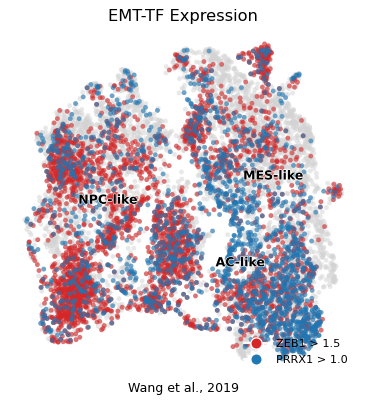

In [5]:
def thresh_for(g, q = 0.90):
    e = adata[:, g].X; e = e.toarray().ravel() if hasattr(e, 'toarray') else np.asarray(e).ravel()
    pos = e[e > 0]
    return float(np.quantile(pos, 0.5)) if pos.size else 0.0
g_plt = {root_tf: ('tab:red', thresh_for(root_tf)), term_tf: ('tab:blue', thresh_for(term_tf))}
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 60, alpha = .5, frameon = False, show = False, ax = ax)
for var, (c, th) in g_plt.items():
    sub = adata[adata[:, var].X > th].copy()
    sc.pl.umap(sub, na_color = c, size = 60, alpha = .6, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=9, label=f'{v} > {th:.1f}')
           for v, (c, th) in g_plt.items()]
ax.legend(handles = handles, frameon = False, loc = 'lower right', fontsize = 9)
ax.set_title('EMT-TF Expression', size = 13)
ax.text(.5, -.05, 'Wang et al., 2019', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches = 'tight')